# Lab 3.4 · PyTorch inference execution

**15–20 minutes · CPU**

Follow the [lab guide](README.md) for setup. Run the setup cell, make a prediction for each exercise, replace each `return None`, and run its check.

In PyTorch, `eval()` switches modules such as dropout and batch normalization into evaluation behavior. `torch.inference_mode()` separately disables gradient tracking and other autograd bookkeeping. An inference service commonly uses both. Compilation with `torch.compile` is a further optimization and may specialize or fuse supported operations. Use a correctness reference before comparing timings.

This lab builds a small projection with dropout and runs it in different modes. A batch variable changes the number of rows passed to the same model. The inputs and weights are generated locally.

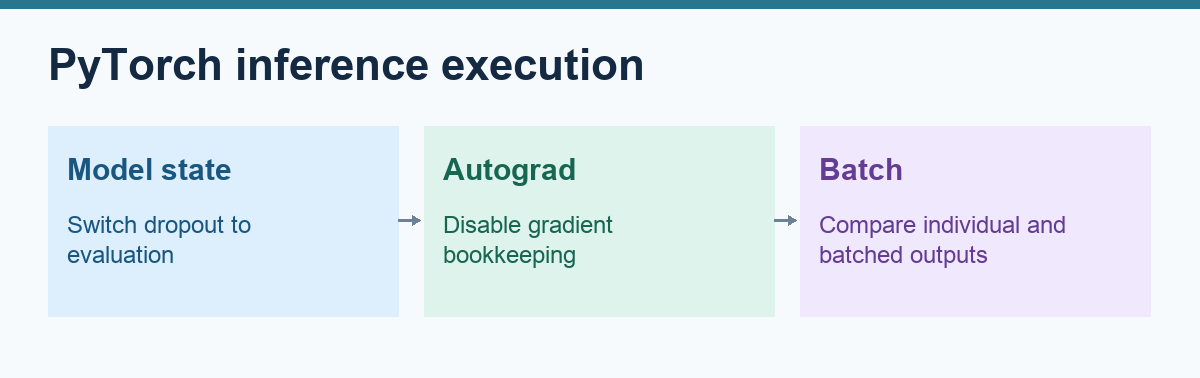

## Exercise map

| Exercise | What you will do | What to look for |
| --- | --- | --- |
| 1. Configure inference | Put the model in evaluation mode and execute the forward pass inside torch.inference_mode(). | Evaluation changes the output because dropout is disabled. Inference mode changes autograd behavior. |
| 2. Compare batch shapes | Use run_inference on each one-row slice and concatenate the results along dimension zero. | Matching outputs makes it meaningful to benchmark the two batch strategies separately. |

In [ ]:
import torch
from torch import nn
torch.manual_seed(7)
model = nn.Sequential(nn.Linear(4, 3, bias=False), nn.Dropout(p=1.0))
with torch.no_grad():
    model[0].weight.fill_(0.25)
inputs = torch.arange(16, dtype=torch.float32).reshape(4, 4)
print("Training output:", model.train()(inputs))

## Exercise 1. Configure inference

Put the model in evaluation mode and execute the forward pass inside torch.inference_mode().

In [ ]:
def run_inference(model, inputs):
    return None

In [ ]:
output = run_inference(model, inputs)
if output is not None:
    assert not model.training and not output.requires_grad
    assert torch.equal(output[:, 0], torch.tensor([1.5, 5.5, 9.5, 13.5]))
    print("PASS — dropout disabled and gradients off:", output)

### Read the result

Evaluation changes the output because dropout is disabled. Inference mode changes autograd behavior.

## Exercise 2. Compare batch shapes

Use run_inference on each one-row slice and concatenate the results along dimension zero.

In [ ]:
def run_by_row(model, inputs):
    return None

In [ ]:
if output is not None:
    rows = run_by_row(model, inputs)
    if rows is not None:
        assert rows.shape == (4, 3)
        torch.testing.assert_close(rows, output)
        torch.testing.assert_close(run_by_row(model, inputs[:2]), output[:2])
        print("PASS — batched and per-row outputs agree")

### Read the result

Matching outputs makes it meaningful to benchmark the two batch strategies separately.

## Optional extension

Design an eager versus compiled comparison. Separate first-call compilation from steady-state time, vary batch size, and check parity before timing. On a GPU, synchronize at the measurement boundary.

## Reading

Philip Kiely, *Inference Engineering*, §4.2.1, pp. 102–103.

- [PyTorch inference mode](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad_mode.inference_mode.html)
- [PyTorch compile](https://docs.pytorch.org/docs/stable/generated/torch.compile.html)